# The defaults of `register_srsf`: run time and effect on the result

`register_srsf` has six numerical settings whose defaults were chosen during development on one
dataset (Dorn2012): `max_iter` (Karcher iterations, 20), `tol` (relative change of the template
that stops the iteration, 1e-3), `max_step` (admissible local slopes of the dynamic-programming
path, 6), `nsub` (sub-samples per grid step in the segment-cost integrals, 4), `lam` (elasticity
penalty, `'auto'` = median total variation) and `parallel` (per-observation alignments in
separate processes, off). This notebook measures, for each setting varied one at a time about
the defaults, the run time and the change in the result, on seven datasets of different size,
length, dimensionality and content, and ends with a recommendation per default.

**Datasets** (jiku-data unless noted): `Lencioni2019` (50 × 101), `Gutenberg` (50 × 101),
`Reznick2021` (150 × 150), `Weather` (35 × 365), `Dorn2012` three-component forces (8 × 100 × 3,
multivariate), `Dorn2012` at the original lengths (8 ragged observations registered in real
time, `t='fs=1000'`; from `notebooks/data/`) and `SPM1D_ANOVA2_2x2` (20 × 101, smooth random
fields with no common features).

**Samples.** Each dataset in full; the four univariate sets with J ≥ 35 also as random subsets of
J = 5, 10 and 20 observations, three draws each (seeded), to show how the settings behave on
small samples.

**Settings.** The default, and twelve variations about it: `max_iter` 2, 5, 10; `tol` 1e-2, 1e-4;
`max_step` 3, 4, 8; `nsub` 2, 8; `lam` 0 and 2 × auto. `parallel=True` is timed separately on the
full sets (it does not change the result).

**Measured per run.** Wall time; the number of Karcher iterations used; the maximum and RMS
difference of the warps from the default run on the same observations (`max |Δγ|`, `rms |Δγ|`,
fractions of the domain); the change of the residual sum of squares of the registered data
relative to the default (`ΔSSE`, as a fraction; negative = tighter alignment); and for the
random-field set the SSE ratio after / before registration (the noise-regularity measure of
the power notebook). For every subset run, `max |Δγ|` between the subset run and the full-sample
default run restricted to the same observations is also recorded (`subset vs full`, the
sample-size sensitivity).

**Sizes.** All runs are listed in the tables; the random-subset draws are `N_DRAWS` = 3 per J.
Results are cached in `srsf_defaults_results.pkl`; `make_defaults_notebook.py --simulate`
re-runs every setting (about 20 minutes on two cores).

In [1]:
import sys, os, time, pickle, warnings
for _v in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(_v, '1')
sys.path.insert(0, os.path.abspath('../src'))   # so that this notebook finds registration1d without installation
import numpy as np
from matplotlib import pyplot as plt
import registration1d as reg1d
import jikudata as jd
warnings.filterwarnings('ignore')

CACHE   = 'srsf_defaults_results.pkl'
N_DRAWS = 3
SUBSETS = (5, 10, 20)

DEFAULTS = dict(max_iter=20, tol=1e-3, max_step=6, nsub=4, lam='auto')
SETTINGS = [('default', {})]
for v in (2, 5, 10):       SETTINGS.append((f'max_iter={v}', dict(max_iter=v)))
for v in (1e-2, 1e-4):     SETTINGS.append((f'tol={v:g}', dict(tol=v)))
for v in (3, 4, 8):        SETTINGS.append((f'max_step={v}', dict(max_step=v)))
for v in (2, 8):           SETTINGS.append((f'nsub={v}', dict(nsub=v)))
SETTINGS.append(('lam=0', dict(lam=0)))
SETTINGS.append(('lam=2*auto', dict(lam='2auto')))

def load(name):
    """Return (y, kwargs) with y as register_srsf expects it."""
    if name == 'Dorn2012 (multivariate)':
        return np.asarray(jd.Dorn2012().y, dtype=float), {}
    if name == 'Dorn2012 (real time)':
        with np.load('data/Dorn2012-reduced.npz', allow_pickle=True) as z:
            return [np.asarray(a, dtype=float) for a in z['y']], dict(t='fs=1000')
    return np.asarray(getattr(jd, name)().y, dtype=float), {}

DATASETS = ['Lencioni2019', 'Gutenberg', 'Reznick2021', 'Weather',
            'Dorn2012 (multivariate)', 'Dorn2012 (real time)', 'SPM1D_ANOVA2_2x2']
SUBSET_DATASETS = ['Lencioni2019', 'Gutenberg', 'Reznick2021', 'Weather']

def take(y, idx):
    return [y[i] for i in idx] if isinstance(y, list) else y[idx]

def run_one(y, extra, setting):
    kw = dict(DEFAULTS); kw.update(setting); kw.update(extra)
    if kw['lam'] == '2auto':
        q  = reg1d.srsf.srsf(y if not isinstance(y, list) else reg1d.register_linear(y, n=101).y)
        kw['lam'] = 2.0 * reg1d.srsf.auto_lam(q)
    t0 = time.time()
    try:
        r = reg1d.register_srsf(y, **kw)
    except RuntimeError as err:                   # e.g. max_step too small for the length ratio
        return dict(seconds=time.time() - t0, niter=0, lam=kw['lam'], error=str(err))
    return dict(seconds=time.time() - t0, niter=r.info['niter'], lam=r.info['lam'],
                warps=r.warps.asarray().astype(np.float32), sse=r.sse()[1], sse0=r.sse()[0])

def run_all():
    results = {}
    if os.path.exists(CACHE):
        with open(CACHE, 'rb') as f:
            results = pickle.load(f)
    for name in DATASETS:
        y, extra = load(name)
        J = len(y)
        samples = [('full', np.arange(J))]
        if name in SUBSET_DATASETS:
            for n in SUBSETS:
                for k in range(N_DRAWS):
                    rng = np.random.default_rng(1000 * n + k)
                    samples.append((f'J={n} draw {k}', np.sort(rng.choice(J, n, replace=False))))
        for sname, idx in samples:
            for label, setting in SETTINGS:
                key = (name, sname, label)
                if key in results:
                    continue
                results[key] = dict(run_one(take(y, idx), extra, setting), idx=idx)
                print(f'{name:26s} {sname:14s} {label:12s} {results[key]["seconds"]:7.1f} s  niter {results[key]["niter"]:2d}'
                      + ('  FAILED: ' + results[key]['error'] if 'error' in results[key] else ''), flush=True)
                with open(CACHE, 'wb') as f:
                    pickle.dump(results, f)
        key = (name, 'full', 'parallel')
        if key not in results:
            results[key] = dict(run_one(y, extra, dict(parallel=True)), idx=np.arange(J))
            print(f'{name:26s} {"full":14s} {"parallel":12s} {results[key]["seconds"]:7.1f} s', flush=True)
            with open(CACHE, 'wb') as f:
                pickle.dump(results, f)
    return results

if __name__ == '__main__' and '--simulate' in sys.argv:
    run_all()

In [2]:
results = run_all()        # loads the cache; runs the study (about 20 minutes) if the cache is absent
print(len(results), 'runs')

def compare(name, sname, label):
    """Differences of one run from the default run on the same sample."""
    r, r0 = results[(name, sname, label)], results[(name, sname, 'default')]
    if 'error' in r:
        return dict(seconds=r['seconds'], niter=0, dmax=np.nan, drms=np.nan, dsse=np.nan, ratio=np.nan, error=r['error'])
    d     = np.abs(r['warps'] - r0['warps'])
    return dict(seconds=r['seconds'], niter=r['niter'], dmax=d.max(), drms=np.sqrt((d**2).mean()),
                dsse=(r['sse'] - r0['sse']) / r0['sse'], ratio=r['sse'] / r['sse0'])

def subset_vs_full(name, sname, label):
    """max |Δγ| between a subset run and the full-sample default run on the same observations."""
    r, rf = results[(name, sname, label)], results[(name, 'full', 'default')]
    return np.abs(r['warps'] - rf['warps'][r['idx']]).max()

LABELS = [l for l, _ in SETTINGS]

566 runs


## Tables: full datasets

One row per setting; columns are the wall time (seconds, two cores, one BLAS thread), the
number of Karcher iterations used, the maximum and RMS warp difference from the default run,
the relative change of the registered-data residual (negative = smaller residual than the
default), and the SSE ratio after / before registration. The last row times `parallel=True`.

In [3]:
for name in DATASETS:
    y, _ = load(name)
    shape = f'J={len(y)}' + (f', Q={y.shape[1]}' if not isinstance(y, list) else ' (ragged)') + (f', D={y.shape[2]}' if not isinstance(y, list) and y.ndim == 3 else '')
    print(f'\n=== {name}  ({shape})   lam(auto) = {results[(name, "full", "default")]["lam"]:.3g}')
    print(f"{'setting':14s} {'seconds':>8s} {'niter':>6s} {'max|dg|':>8s} {'rms|dg|':>8s} {'dSSE':>8s} {'ratio':>7s}")
    for label in LABELS:
        c = compare(name, 'full', label)
        if 'error' in c:
            print(f"{label:14s} {c['seconds']:8.1f}   failed: {c['error']}")
            continue
        print(f"{label:14s} {c['seconds']:8.1f} {c['niter']:6d} {c['dmax']:8.3f} {c['drms']:8.4f} {c['dsse']:+8.3f} {c['ratio']:7.3f}")
    c = results[(name, 'full', 'parallel')]
    print(f"{'parallel':14s} {c['seconds']:8.1f} {c['niter']:6d}")


=== Lencioni2019  (J=50, Q=101)   lam(auto) = 137
setting         seconds  niter  max|dg|  rms|dg|     dSSE   ratio
default             2.6     11    0.000   0.0000   +0.000   0.716
max_iter=2          0.5      2    0.012   0.0026   +0.000   0.716
max_iter=5          1.2      5    0.010   0.0011   -0.002   0.714
max_iter=10         2.4     10    0.002   0.0001   -0.000   0.716
tol=0.01            0.7      3    0.010   0.0020   -0.003   0.714
tol=0.0001          3.3     13    0.002   0.0001   +0.000   0.716
max_step=3          1.7     17    0.024   0.0044   +0.028   0.736
max_step=4          1.5     11    0.021   0.0029   +0.002   0.717
max_step=8          3.6      9    0.011   0.0022   -0.011   0.708
nsub=2              2.3     10    0.020   0.0007   -0.002   0.715
nsub=8              3.4     12    0.010   0.0004   +0.000   0.716
lam=0               2.9     12    0.037   0.0053   -0.020   0.702
lam=2*auto          3.4     14    0.033   0.0039   +0.028   0.736
parallel            1.4  

## Figures: one per setting

Left: wall time relative to the default run on the same sample. Right: maximum warp difference
from the default run (fraction of the domain). One line per dataset, full samples; the shaded
band shows the range over the J = 5, 10, 20 subset draws where available. A difference of 0.01
is one node of a Q = 101 grid.

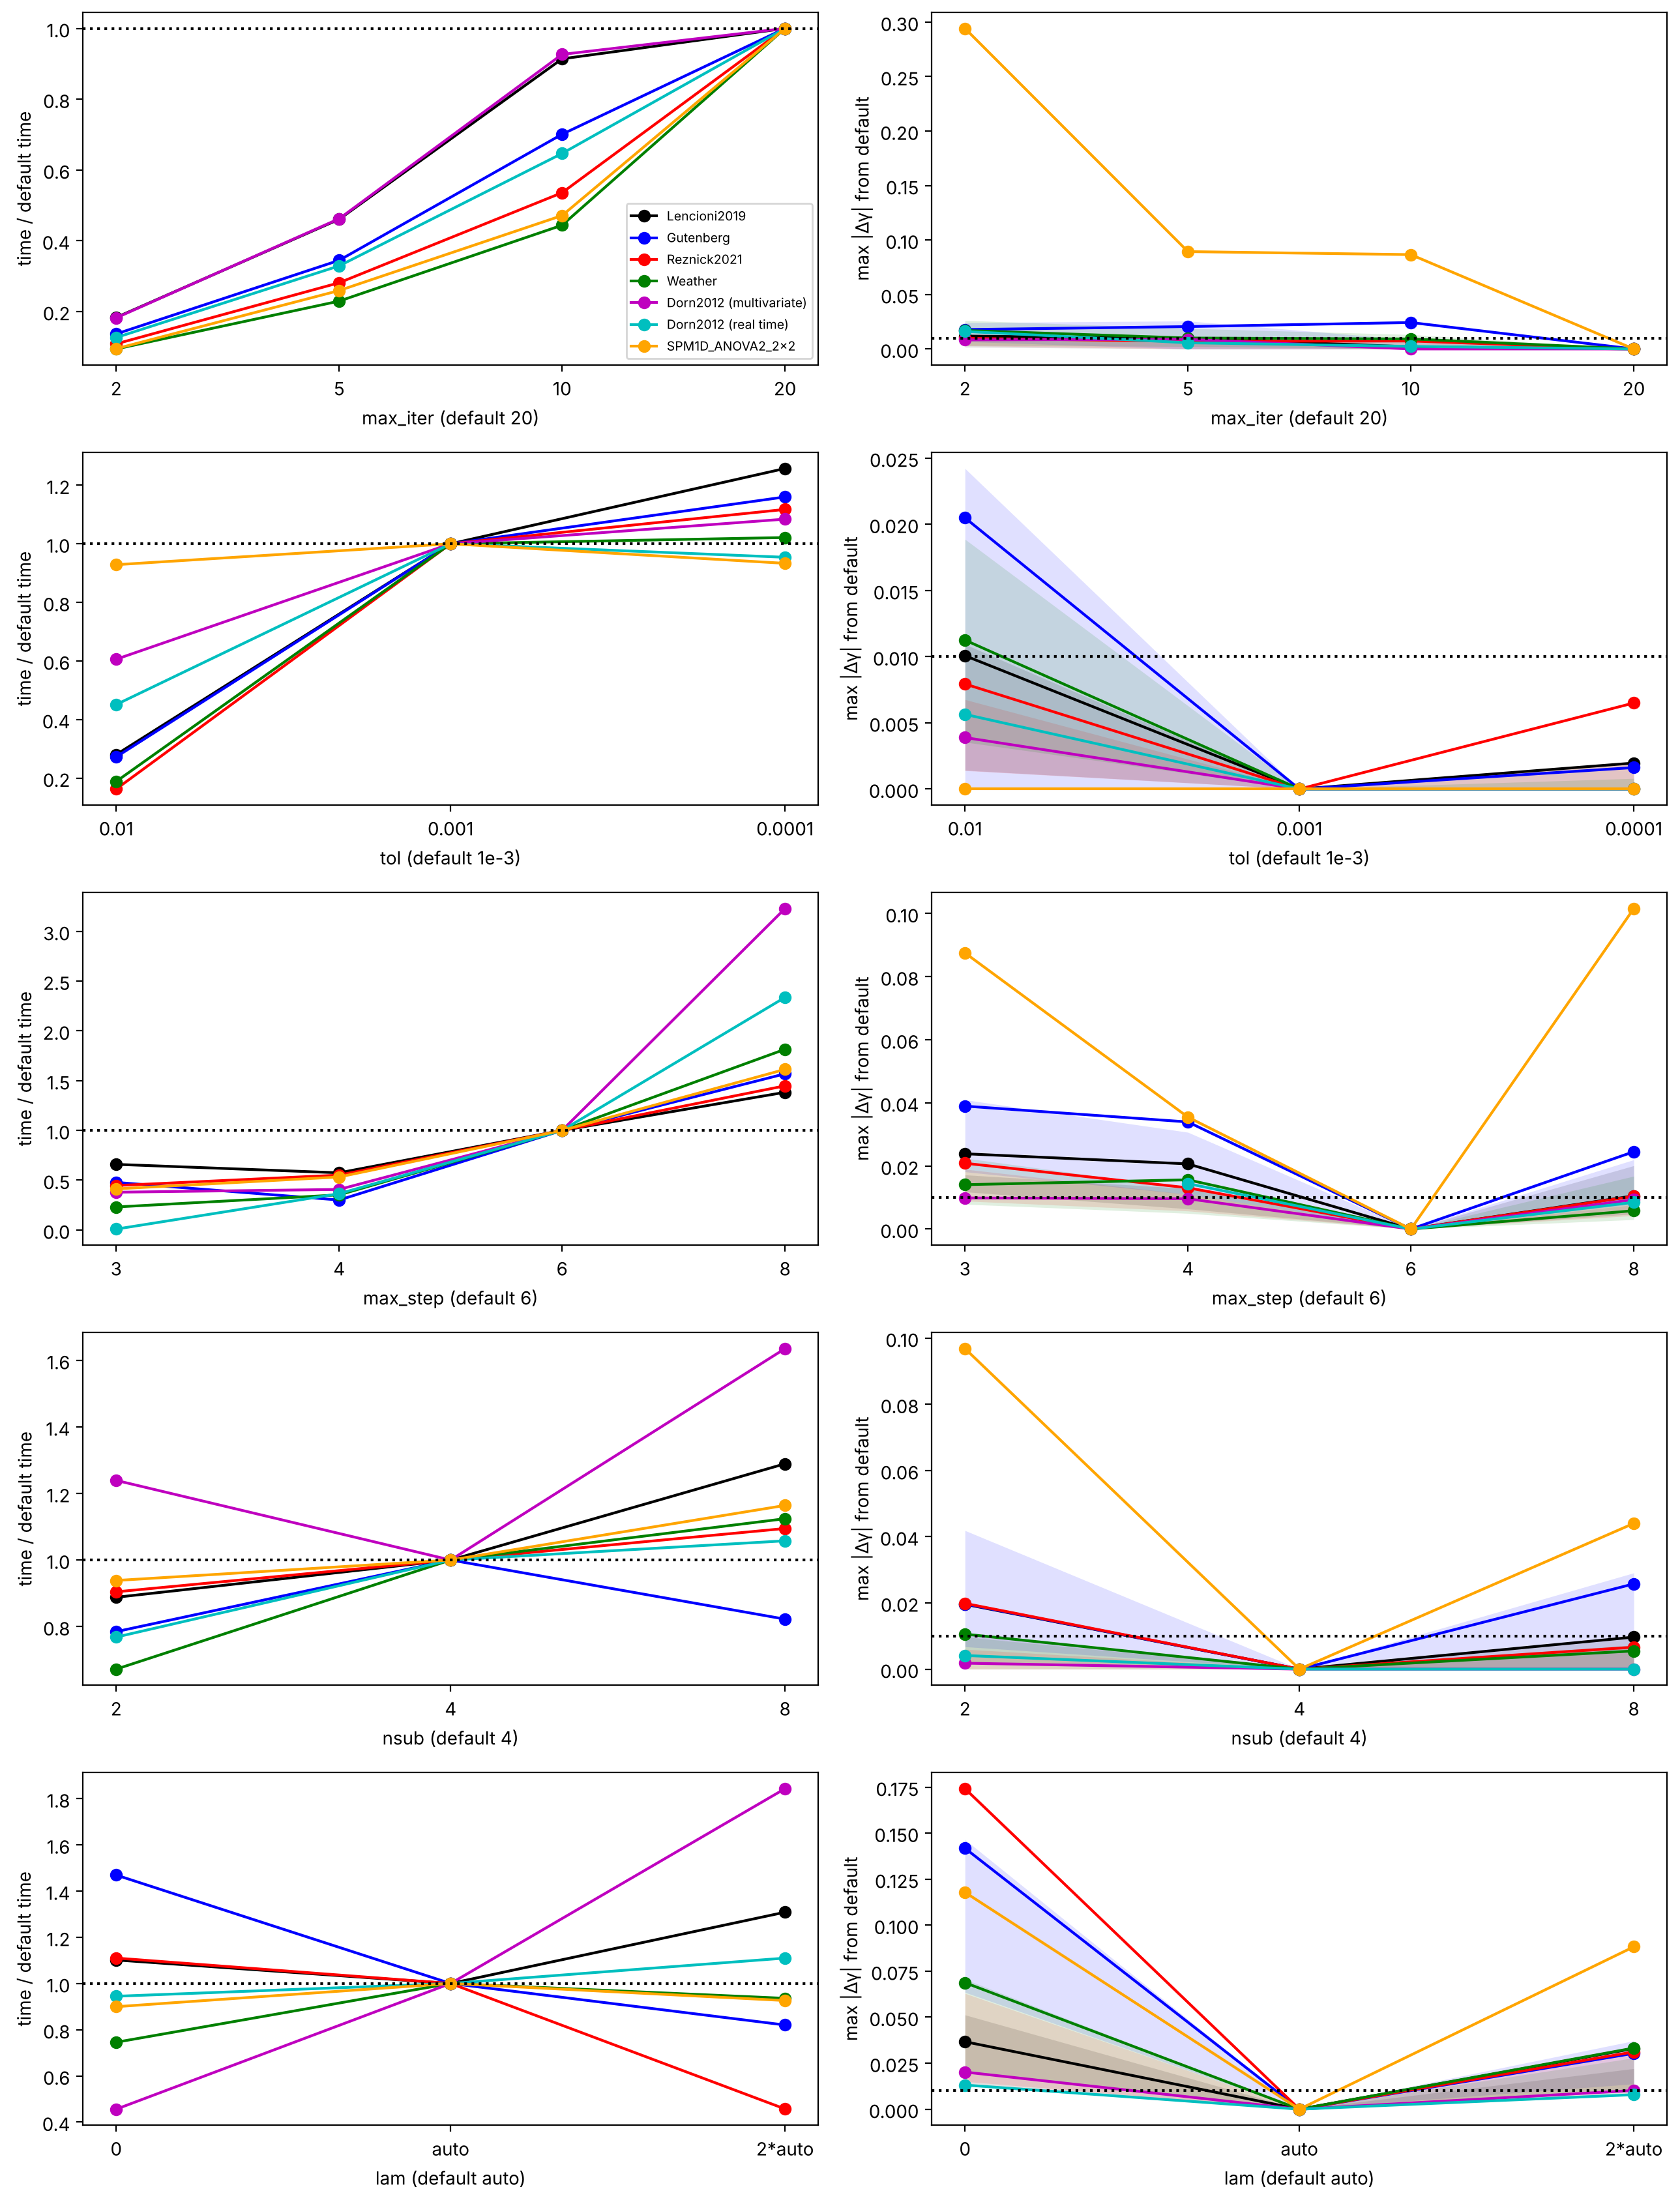

In [4]:
PARAMS = [('max_iter', [2, 5, 10, 20], 'max_iter (default 20)'),
          ('tol',      [1e-2, 1e-3, 1e-4], 'tol (default 1e-3)'),
          ('max_step', [3, 4, 6, 8], 'max_step (default 6)'),
          ('nsub',     [2, 4, 8], 'nsub (default 4)'),
          ('lam',      ['0', 'auto', '2*auto'], 'lam (default auto)')]
def label_of(p, v):
    if p == 'lam':
        return 'default' if v == 'auto' else f'lam={v}'
    if v == DEFAULTS[p]:
        return 'default'
    return f'{p}={v:g}' if p == 'tol' else f'{p}={v}'

colors = dict(zip(DATASETS, ['k', 'b', 'r', 'g', 'm', 'c', 'orange']))
fig, AX = plt.subplots(len(PARAMS), 2, figsize=(13, 3.4 * len(PARAMS)))
for row, (p, values, xlabel) in zip(AX, PARAMS):
    for name in DATASETS:
        labels = [label_of(p, v) for v in values]
        tf = [compare(name, 'full', l)['seconds'] / results[(name, 'full', 'default')]['seconds'] for l in labels]
        df = [compare(name, 'full', l)['dmax'] for l in labels]
        x  = list(range(len(values)))
        row[0].plot(x, tf, 'o-', color=colors[name], label=name)
        row[1].plot(x, df, 'o-', color=colors[name], label=name)
        if name in SUBSET_DATASETS:
            subs = [f'J={n} draw {k}' for n in SUBSETS for k in range(N_DRAWS)]
            lo = [min(compare(name, s, l)['dmax'] for s in subs) for l in labels]
            hi = [max(compare(name, s, l)['dmax'] for s in subs) for l in labels]
            row[1].fill_between(x, lo, hi, color=colors[name], alpha=0.12, lw=0)
    for ax in row:
        ax.set_xticks(range(len(values))); ax.set_xticklabels([str(v) for v in values]); ax.set_xlabel(xlabel)
    row[0].set_ylabel('time / default time'); row[0].axhline(1, color='k', ls=':')
    row[1].set_ylabel('max |Δγ| from default'); row[1].axhline(0.01, color='k', ls=':')
AX[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Small samples

For the four large univariate datasets: the maximum warp difference between each subset run and
the full-sample default run on the same observations (`subset vs full`, averaged over the three
draws), for the default and for the cheaper settings. This measures how much the registration
of a given observation depends on the sample it is registered with, and whether the cheaper
settings change that.

In [5]:
cheap = ['default', 'max_iter=5', 'max_iter=10', 'max_step=4', 'nsub=2', 'lam=0', 'lam=2*auto']
for name in SUBSET_DATASETS:
    print(f'\n=== {name}: max |Δγ| subset run vs full-sample default run, mean over {N_DRAWS} draws')
    print(f"{'setting':14s} " + ' '.join(f'{"J="+str(n):>8s}' for n in SUBSETS) + '      seconds (J=5 / 10 / 20)')
    for label in cheap:
        d = [np.mean([subset_vs_full(name, f'J={n} draw {k}', label) for k in range(N_DRAWS)]) for n in SUBSETS]
        s = [np.mean([results[(name, f'J={n} draw {k}', label)]['seconds'] for k in range(N_DRAWS)]) for n in SUBSETS]
        print(f'{label:14s} ' + ' '.join(f'{v:8.3f}' for v in d) + '      ' + ' / '.join(f'{v:.1f}' for v in s))


=== Lencioni2019: max |Δγ| subset run vs full-sample default run, mean over 3 draws
setting             J=5     J=10     J=20      seconds (J=5 / 10 / 20)
default           0.016    0.024    0.017      0.1 / 0.3 / 0.7
max_iter=5        0.016    0.024    0.017      0.1 / 0.2 / 0.5
max_iter=10       0.016    0.024    0.017      0.2 / 0.3 / 0.6
max_step=4        0.016    0.025    0.019      0.1 / 0.2 / 0.4
nsub=2            0.018    0.024    0.017      0.1 / 0.2 / 0.7
lam=0             0.021    0.026    0.023      0.2 / 0.3 / 0.9
lam=2*auto        0.019    0.027    0.022      0.1 / 0.3 / 1.1

=== Gutenberg: max |Δγ| subset run vs full-sample default run, mean over 3 draws
setting             J=5     J=10     J=20      seconds (J=5 / 10 / 20)
default           0.019    0.016    0.019      0.2 / 0.5 / 0.7
max_iter=5        0.019    0.017    0.022      0.1 / 0.2 / 0.5
max_iter=10       0.019    0.016    0.019      0.2 / 0.4 / 0.7
max_step=4        0.021    0.022    0.025      0.1 / 0.3 / 0.

## Iterations actually used

`max_iter=20` is a ceiling; the iteration stops earlier when the relative change of the template
falls below `tol`. The number of iterations used by the default run, per dataset and sample size.

In [6]:
print(f"{'dataset':26s} {'full':>6s} " + ' '.join(f'{"J="+str(n):>6s}' for n in SUBSETS))
for name in DATASETS:
    row = [results[(name, 'full', 'default')]['niter']]
    if name in SUBSET_DATASETS:
        row += [np.mean([results[(name, f'J={n} draw {k}', 'default')]['niter'] for k in range(N_DRAWS)]) for n in SUBSETS]
    print(f'{name:26s} ' + ' '.join(f'{v:6.1f}' for v in row))

dataset                      full    J=5   J=10   J=20
Lencioni2019                 11.0    5.7    5.7    7.3
Gutenberg                    14.0    7.0   10.0    8.0
Reznick2021                  18.0    8.3   11.0   16.3
Weather                      20.0   11.7   10.3   14.7
Dorn2012 (multivariate)      11.0
Dorn2012 (real time)         15.0
SPM1D_ANOVA2_2x2             20.0


## Summary and recommendations

Differences are in fractions of the domain; 0.01 is one node of a Q = 101 grid. "Signal" sets
are the six real datasets; the random-field set behaves differently and is discussed separately.

**`max_iter` (20): keep 20, but it is the main cost lever.** On the signal sets the default
stops after 11-20 iterations and the warps after 5 iterations differ from it by at most 0.010
(max) and 0.001-0.003 (RMS), for a 3.5-4× saving; after 10 iterations the maximum difference is
0.002-0.024 (Gutenberg's 0.024 is one observation; RMS 0.0009). The registered-data residual
changes by under 2 %. On the random-field set the iteration never converges (20 of 20 at every
tolerance) and stopping early changes the warps by 0.09-0.29, i.e. the warps of noise are
arbitrary at any iteration count. Recommendation: keep 20 as the default because the cost of
convergence is modest after the dynamic-programming speed-up, and document `max_iter=5` as the
setting for exploratory work; a non-converged run (niter == max_iter) is a sign of featureless
data and could be reported with a warning.

**`tol` (1e-3): keep.** 1e-4 changes the warps by ≤ 0.006 at up to 20 % more time; 1e-2 stops
after 3-7 iterations and is equivalent to `max_iter=5` (differences ≤ 0.020).

**`max_step` (6): keep.** Smaller values are cheaper (3: 0.4-0.6×, 4: 0.45-0.7×) but change the
warps by 0.013-0.039 on the signal sets and raise the residual by up to 3 %, and `max_step=3` is
infeasible for real-time registration of observations whose lengths differ from the reference
grid by more than a factor of three (Dorn2012: 299-383 samples onto 101). `max_step=8` costs
1.4-1.8× for differences of 0.006-0.025 and residual changes within 1 %, i.e. 6 is already in
the flat part of the curve.

**`nsub` (4): keep.** 2 saves 10-30 % and changes the warps by up to 0.020; 8 costs 5-30 % for
≤ 0.026 (0.000-0.010 on five of seven sets). The segment-cost integral is not the limiting
approximation.

**`lam` ('auto'): keep, and it is the setting that matters.** Setting `lam=0` changes the warps
by 0.04-0.17 on the signal sets and on Gutenberg (lam(auto) = 0.93, nearly flat curves) produces
warps that *increase* the residual by 34 % (SSE ratio 1.06): the unpenalised alignment is driven
by noise. Doubling the penalty changes the warps by 0.03 and raises the residual by 1-4 %. The
auto rule scales correctly across data of very different magnitude (lam from 0.9 to 5400) and
needs no user input.

**`parallel` (off): keep off as the default, recommend on for J ≥ 50.** Two cores gave 1.8-1.9×
on the three large sets and nothing on J = 8 (process start-up dominates). The result is
unchanged.

**Small samples.** Registering 5-20 observations instead of all gives warps that differ from the
full-sample registration of the same observations by 0.015-0.030 at the default settings, on
every signal set; the cheaper settings (`max_iter=5`, `nsub=2`, `max_step=4`) add 0.000-0.012 to
that and `lam=0` adds up to 0.1. The sample-size effect is therefore of the same size as the
effect of the cheaper settings and larger than the effect of `tol` or `nsub`: a user worried
about accuracy should worry about J before worrying about these settings, with the exception of
`lam`.

**One observation outside the defaults question.** On the three-component Dorn2012 data the
SSE after registration is 26 % *larger* than before (ratio 1.26 under every setting): the vector
SRSF is dominated by the largest-slope component and the warps that align it increase the
residual of the others. Per-component standardisation before the vector SRSF (raised in the
jiku-data notebook) is the likely remedy and should be tested separately.

**Costs (two cores, one BLAS thread each, after the dynamic-programming speed-up).** Default run:
Lencioni2019 2.6 s, Gutenberg 3.3 s, Reznick2021 22 s, Weather 23 s, the small sets ≤ 2 s; the
whole study (566 runs) took about 12 minutes.